# Regularized GLM--Neural Network Hybrids for Insurance Pricing
CAS ETH in Machine Learning in Finance and Insurance Innovation Project

Leonhard Vogt, 31.10.2026

This project explores the use of a mixed model including FNN and GLM components.
The purpose is the study of the reqularization and joint training of the components.

The setup of the GLM in statsmodels and its input data preparation are taken from https://github.com/wueth/AITools4Actuaries/blob/main/Ch3_02_Poisson_GLM.ipynb

The FNN is taken from https://github.com/wueth/AITools4Actuaries/blob/main/Ch5_07_CANN.ipynb

Contributed by the author are the implementation of the GLM in Keras and the hybrid model with regularization.


## Table of contents
- [1. Setup and evaluation](#cell-5YKlk2Q9Xobw)
  - [1.1 Imports and run configuration](#cell-68lvmJKEOMhp)
  - [1.2 Model registry and evaluation functions](#cell-0ZVdoO4yrK7H)
  - [1.3 Data Download](#cell-lkl3-B4yVa3r)
- [2. Baseline GLM](#cell-_PgP3Z7qNzlj)
  - [2.1 GLM feature construction](#cell-fF1Vvyq8Voim)
  - [2.2 Estimation in statsmodels](#cell-dL6CwMtPrZ5h)
- [3. GLM implementation in Keras](#cell-Wnh8ZwtFOgGA)
  - [3.1 Dummy encoding and parameter transfer](#cell-47939027)
  - [3.2 Model definition and initialisation control](#cell-vCoM1USlrpjl)
  - [3.3 Optimisation and stability experiments](#cell-6Yuzya6Jruww)
  - [3.4 Results and report tables](#cell-2PsR1WJhryd6)
  - [3.5 Relationship between Poisson loss and deviance](#cell-KN9ukFBTaL7V)
- [4. FNN and frozen CANN benchmarks](#cell-3rtBYDSlNJKK)
  - [4.1 Neural feature construction](#cell-JgTN9WHDazB-)
  - [4.2 FNN architecture](#cell-3cbF9uzPsSiM)
  - [4.3 CANN construction and GLM reproduction](#cell--8CJsnAKsWFb)
  - [4.4 Benchmark training](#cell-VMlYHQwWsgUt)
  - [4.5 Training-history comparison](#cell-mApgFZlKsi6b)
- [5. Jointly trained regularized hybrid](#cell-XZ-M7xeKcpyR)
  - [5.1 Architecture and regularization](#cell-14L--lRfNVA2)
  - [5.2 Initialisation and GLM reproduction](#cell-ih4PSrjxc5D_)
  - [5.3 Regularization parameter sweep](#cell-Xz0ktMUfdQnY)
- [6. Results and structural diagnostics](#cell-beKLxIhOs2IX)
  - [6.1 Predictive performance and calibration](#cell-Om5tKdq8s_VR)
  - [6.2 Regularization path and validation loss](#cell-DthlKkRxtNt9)
  - [6.3 GLM coefficient paths](#cell-Gdbdux_TtKwI)
  - [6.4 FNN correction statistics and distribution](#cell-l0mzRs9wtoFO)

## 1. Setup and evaluation



### 1.1 Imports and run configuration

In [1]:
from types import SimpleNamespace
import os
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats
from scipy.ndimage import gaussian_filter1d
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_poisson_deviance
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OrdinalEncoder,
    StandardScaler,
)
import statsmodels.api as sm
from statsmodels.formula.api import glm
import tensorflow as tf
from tensorflow import keras
try:
  from google.colab import files
except ImportError:
  files = SimpleNamespace(download=lambda _: None)

In [2]:
# a helper to allow quick run of notebook
QUICK_MODE = True

def effective_epochs(n):
  if QUICK_MODE:
    print("WARNING: Not running all epochs due to QUICK_MODE")
    return 1
  else:
    return n

### 1.2 Model registry and evaluation functions

In [3]:
# a global list of all models
model_list = []

In [4]:
def calculate_deviance(model_run):
  # Calculate in-sample and out-of-sample deviance using sklearn
  # For better visibility we scale with 100
  for dataset_name, dataset in [("Training", model_run.train), ("Testing", model_run.test)]:
    dataset.deviance = 100 * mean_poisson_deviance(
      dataset.target / dataset.exposure,
      dataset.prediction,
      sample_weight=dataset.exposure
    )

    actual_claims = np.asarray(dataset.target).ravel()
    exposure = np.asarray(dataset.exposure).ravel()
    predicted_rates = np.asarray(dataset.prediction).ravel()

    dataset.keras_poisson = np.mean(exposure * ( predicted_rates - actual_claims/exposure * np.log(predicted_rates) ) )

    predicted_claims = predicted_rates * exposure
    relative_scoring = actual_claims.sum() / predicted_claims.sum()
    print(f"{dataset_name} Deviance = {dataset.deviance:.3f} Keras Poisson = {dataset.keras_poisson:.5f}"
      f"  Total Actual Claims: {actual_claims.sum():.2f}"
      f"  Total Predicted Claims: {predicted_claims.sum():.2f}"
      f"  Relative Scoring (Actual / Predicted): {relative_scoring:.4f}")

In [5]:
# a less verbose training output
class OneLineProgress(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        val_loss = ""
        if "val_loss" in logs:
            val_loss = f" - val_loss: {logs['val_loss']:.6f}"
        print(
            f"\rEpoch {epoch + 1}/{self.params['epochs']} "
            f"- loss: {logs['loss']:.6f} {val_loss}",
            end="",
            flush=True,
        )

    def on_train_end(self, logs=None):
        print()

### 1.3 Data Download

The data is the same as the original sources, including the test-training split.

In [6]:
# URL of the zip file
zip_url = "https://people.math.ethz.ch/~wueth/AITools/Data.zip"
zip_file_name = "Data.zip"

if not os.path.exists(zip_file_name):
  print(f"Downloading {zip_file_name}...")
  response = requests.get(zip_url)
  response.raise_for_status() # Raise an exception for HTTP errors

  with open(zip_file_name, "wb") as f:
      f.write(response.content)
else:
  print(f"{zip_file_name} already exists.")

# Unzip the file
print(f"Unzipping {zip_file_name}...")
with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
    zip_ref.extractall(".") # Extract to the current directory
print("Unzipping complete.")


Unzipping Data.zip...
Unzipping complete.


In [7]:
df = pd.read_parquet("Data/freMTPL2freq.parquet")
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678007 entries, 0 to 678006
Data columns (total 14 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   IDpol       678007 non-null  float64 
 1   Exposure    678007 non-null  float64 
 2   Area        678007 non-null  category
 3   VehPower    678007 non-null  int32   
 4   VehAge      678007 non-null  int32   
 5   DrivAge     678007 non-null  int32   
 6   BonusMalus  678007 non-null  int32   
 7   VehBrand    678007 non-null  category
 8   VehGas      678007 non-null  category
 9   Density     678007 non-null  int32   
 10  Region      678007 non-null  category
 11  ClaimTotal  678007 non-null  float64 
 12  ClaimNb     678007 non-null  float64 
 13  LearnTest   678007 non-null  object  
dtypes: category(4), float64(4), int32(5), object(1)
memory usage: 41.4+ MB
None


,IDpol,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimTotal,ClaimNb,LearnTest
0,4156370.0,0.06,D,6,6,20,100,B2,Regular,525,R82,0.0,0.0,L
1,4006798.0,0.29,E,6,7,29,59,B12,Diesel,2498,R72,0.0,0.0,L
2,6084964.0,0.46,C,7,10,27,68,B1,Diesel,123,R82,0.0,0.0,L
3,2228865.0,0.08,D,4,15,34,50,B2,Regular,1109,R24,0.0,0.0,L
4,4141911.0,1.00,A,5,22,44,50,B3,Diesel,34,R72,0.0,0.0,L


In [8]:
mtpl = SimpleNamespace(
    raw_data = SimpleNamespace(
      training_data_raw = df[df.LearnTest == "L"].reset_index(drop=True),
      testing_data_raw = df[df.LearnTest == "T"].reset_index(drop=True),
    )
)

## 2. Baseline GLM

### 2.1 GLM feature construction

In [9]:
def preprocess_mtpl():
  """ for comparability the preprocessing as well as the data is taken from
  https://github.com/wueth/AITools4Actuaries/blob/main/Ch3_02_Poisson_GLM.ipynb"""

  # DrivAge: 31-40 is placed first so it becomes the GLM reference level
  _driv_age_bins = [17, 20, 25, 30, 40, 50, 70, 101]
  _driv_age_labels = ["18-20", "21-25", "26-30", "31-40", "41-50", "51-70", "71+"]
  _driv_age_ref_first = ["31-40"] + [lev for lev in _driv_age_labels if lev != "31-40"]

  # --- preprocessing functions specific for single covariates ---
  def _area_encode(X):
    """Map alphabetical area codes A-F to ordinal integers 1-6."""
    return (X.squeeze().cat.codes + 1.0).to_frame(name="AreaGLM")

  def _vehpower_clip(X):
    """Cap vehicle power at 9 and treat as categorical."""
    return pd.DataFrame({"VehPowerGLM": pd.Categorical(X.squeeze().clip(upper=9))})

  def _vehage_bin(X):
    """Bin vehicle age into three groups: 0-5, 6-12, 12+."""
    return pd.DataFrame({
            "VehAgeGLM": pd.cut(
                X.squeeze(), bins=[-1, 5, 12, 101], labels=["0-5", "6-12", "12+"]
            )})

  def _drivage_bin(X):
      """Bin driver age into seven groups with 31-40 as the reference level."""
      cuts = pd.cut(X.squeeze(), bins=_driv_age_bins, labels=_driv_age_labels)
      return pd.DataFrame(
          {"DrivAgeGLM": pd.Categorical(cuts, categories=_driv_age_ref_first)}
      )

  def _bonusmalus_clip(X):
      """Cap bonus-malus score at 150."""
      return pd.DataFrame({"BonusMalusGLM": X.squeeze().clip(upper=150)})

  def _density_log(X):
      """Log-transform population density."""
      return pd.DataFrame({"DensityGLM": np.log(X.squeeze())})

  def _ft(func, names):
      """Return a FunctionTransformer with fixed output column names."""
      return FunctionTransformer(
          func=func, feature_names_out=lambda self, _: names, check_inverse=False
      )

  # --- assemble the preprocessing pipeline ---
  preprocessor = ColumnTransformer(
    transformers=[
        ("area", _ft(_area_encode, ["AreaGLM"]), ["Area"]),
        ("vehpower", _ft(_vehpower_clip, ["VehPowerGLM"]), ["VehPower"]),
        ("vehage", _ft(_vehage_bin, ["VehAgeGLM"]), ["VehAge"]),
        ("drivage", _ft(_drivage_bin, ["DrivAgeGLM"]), ["DrivAge"]),
        ("bonusmalus", _ft(_bonusmalus_clip, ["BonusMalusGLM"]), ["BonusMalus"]),
        ("density", _ft(_density_log, ["DensityGLM"]), ["Density"]),
        ("passthrough", "passthrough", ["VehBrand", "VehGas", "ClaimNb", "Exposure"]),
    ],
    verbose_feature_names_out=False,
  )
  # Fit preprocessor on learning data only
  preprocessor.set_output(transform="pandas").fit(mtpl.raw_data.training_data_raw)

  mtpl.glm_data = SimpleNamespace(
    training_data = preprocessor.transform(mtpl.raw_data.training_data_raw).copy(),
    testing_data = preprocessor.transform(mtpl.raw_data.testing_data_raw).copy(),
  )
preprocess_mtpl()



### 2.2 Estimation in statsmodels

In [10]:
glm1 = SimpleNamespace(
    name = "glm1",
  description = "The baseline GLM from AITools4Actuaries",
  train = SimpleNamespace(target = mtpl.glm_data.training_data["ClaimNb"],
                          exposure = mtpl.glm_data.training_data['Exposure']),
  test = SimpleNamespace(target = mtpl.glm_data.testing_data["ClaimNb"],
                         exposure = mtpl.glm_data.testing_data['Exposure']),
)

glm1.model = glm(
      "ClaimNb ~ DrivAgeGLM + VehBrand + VehGas + DensityGLM + AreaGLM",
      data=mtpl.glm_data.training_data,
      offset=np.log(mtpl.glm_data.training_data["Exposure"]),
      family=sm.families.Poisson(),
  )

glm1.results = glm1.model.fit()
print(glm1.results.summary())
model_list.append(glm1)
glm1.train.prediction = glm1.results.predict(mtpl.glm_data.training_data)
glm1.test.prediction = glm1.results.predict(mtpl.glm_data.testing_data)


                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               610206
Model:                            GLM   Df Residuals:                   610186
Model Family:                 Poisson   Df Model:                           19
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -98513.
Date:                Wed, 28 Oct 2026   Deviance:                   1.5138e+05
Time:                        19:55:09   Pearson chi2:                 1.02e+06
No. Iterations:                     7   Pseudo R-squ. (CS):           0.004052
Covariance Type:            nonrobust                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -3.2590    

In [11]:
calculate_deviance(glm1)

# check that we properly reproduce the base case from AITools4Actuaries
assert abs(glm1.train.deviance - 46.954) < 0.0006, f"training deviance is {glm1.train.deviance:.3f}, expected 46.954"
assert abs(glm1.test.deviance - 47.179) < 0.0006, f"test deviance is {glm1.test.deviance:.3f}, expected 47.179"

Training Deviance = 46.954 Keras Poisson = 0.13835  Total Actual Claims: 23738.00  Total Predicted Claims: 23738.00  Relative Scoring (Actual / Predicted): 1.0000
Testing Deviance = 47.179 Keras Poisson = 0.13874  Total Actual Claims: 2645.00  Total Predicted Claims: 2650.74  Relative Scoring (Actual / Predicted): 0.9978


In [12]:
def glm_to_keras(params, keras_columns):
    """ Extract parameters from a statsmodels GLM parameter object and transform them for consumptions in a Keras model

    Return (kernel, bias) for a Keras Dense(1) layer."""
    p = params.copy()

    # statsmodels/Patsy names -> get_dummies names
    p.index = (p.index
               .str.replace(r"\[T\.(.*?)\]", r"_\1", regex=True))

    bias = p.pop("Intercept")
    kernel = p.reindex(keras_columns)

    if kernel.isna().any():
        raise ValueError(f"Missing GLM parameters: {kernel[kernel.isna()].index.tolist()}")

    return kernel.to_numpy().reshape(-1, 1), np.array([bias])

## 3. GLM implementation in Keras


### 3.1 Dummy encoding and parameter transfer

Create one-hot encoded versions of the training and testing dataframes. Contrary to `statsmodels` this is not automatic. `pd.get_dummies` will automatically identify and convert categorical columns (object or category dtype) into a numerical format, which can be useful for other modeling approaches.

In [13]:
features = ["DrivAgeGLM", "VehBrand", "VehGas", "DensityGLM", "AreaGLM"]

# Perform one-hot encoding on training and testing data
# pd.get_dummies automatically handles categorical (object/category) columns
mtpl.glm_data.training_data_1h = pd.get_dummies(mtpl.glm_data.training_data[features], drop_first=True, dtype=float)
mtpl.glm_data.testing_data_1h = pd.get_dummies(mtpl.glm_data.testing_data[features], drop_first=True, dtype=float)


### 3.2 Model definition and initialisation control

In [14]:
def create_glm_linear_predictor(n_features, initializer):
    features_input = keras.Input(shape=(n_features,), name='features_input')

    init = {}
    if initializer is not None:
      weights, bias = initializer
      init['kernel_initializer'] = keras.initializers.Constant(weights)
      init['bias_initializer'] = keras.initializers.Constant(bias)

    linear_predictor = keras.layers.Dense(1, name='glm_linear_predictor', activation='linear', **init)(features_input)

    return linear_predictor, features_input


def glm_keras(name, data, initializer, split, batch_size, epochs, keep_best, description, seed=1234):
    tf.keras.utils.set_random_seed(seed)
    model_info = SimpleNamespace(
        name=name,
        description=description,
        constructor='glm_keras',
        initializer= initializer.name if initializer else "None",
        split=split,
        batch_size=batch_size,
        epochs=epochs,
        keep_best=keep_best,
        seed=seed,
        train = SimpleNamespace(target = data.training_data["ClaimNb"],
                            exposure = data.training_data['Exposure'],
                            input = data.training_data_1h),
    test = SimpleNamespace(target = data.testing_data["ClaimNb"],
                          exposure = data.testing_data['Exposure'],
                          input = data.testing_data_1h),
    )

    if initializer is not None:
      initializer = glm_to_keras(initializer.results.params, model_info.train.input.columns)

    input_shape = model_info.train.input.shape[1]

    linear_predictor, features_input = create_glm_linear_predictor(input_shape, initializer)


    dense_output = keras.layers.Activation("exponential")(linear_predictor)

    # Create the Keras Model
    model_info.model = keras.Model(inputs=features_input, outputs=dense_output)

    if epochs is not None:
      callbacks = [OneLineProgress()]
      if keep_best:
        callbacks.append(keras.callbacks.EarlyStopping(
          monitor="val_loss" if split else "loss",
          patience=epochs,          # effectively prevents early stopping
          restore_best_weights=True,
        ))

      model_info.model.compile(loss="poisson", optimizer="nadam")
      model_info.history = model_info.model.fit(
        model_info.train.input,
        model_info.train.target / model_info.train.exposure,
        sample_weight=model_info.train.exposure,
        validation_split=split,
        batch_size=batch_size,
        epochs=effective_epochs(epochs),
        verbose=0,
        callbacks=callbacks,
      )
    model_info.train.prediction = model_info.model(model_info.train.input, training=False).numpy()
    model_info.test.prediction = model_info.model(model_info.test.input, training=False).numpy()
    calculate_deviance(model_info)
    return model_info


In [15]:
glm_keras_control = glm_keras("glm_keras_control", mtpl.glm_data,
                              initializer=glm1, split=None, batch_size=None, epochs=None, keep_best=False,
                              description="A Keras/Tensorflow model implementing GLM and initialized with GLM coefficients, predicting rate")
model_list.append(glm_keras_control)

Training Deviance = 46.954 Keras Poisson = 0.13835  Total Actual Claims: 23738.00  Total Predicted Claims: 23738.00  Relative Scoring (Actual / Predicted): 1.0000
Testing Deviance = 47.179 Keras Poisson = 0.13874  Total Actual Claims: 2645.00  Total Predicted Claims: 2650.74  Relative Scoring (Actual / Predicted): 0.9978


### 3.3 Optimisation and stability experiments

In [16]:
for batch_size, epochs in [(5000,200), (50000, 2000), (200000, 4000)]:
  for split in [None, 0.1]:
    model_list.append(
        glm_keras("glm_keras_trained", mtpl.glm_data,
                  initializer=None, split=split, batch_size=batch_size, epochs=epochs, keep_best=True,
                  description=f"A Keras/Tensorflow model implementing GLM"))
    model_list.append(
        glm_keras("glm_keras_train_init", mtpl.glm_data,
                  initializer=glm1, split=split, batch_size=batch_size, epochs=epochs//10, keep_best=False,
                  description=f"A Keras/Tensorflow model implementing GLM and initialized with GLM coefficients")
        )


Epoch 1/1 - loss: 3.274400 
Training Deviance = 659.377 Keras Poisson = 1.75617  Total Actual Claims: 23738.00  Total Predicted Claims: 1098974.86  Relative Scoring (Actual / Predicted): 0.0216
Testing Deviance = 660.993 Keras Poisson = 1.76679  Total Actual Claims: 2645.00  Total Predicted Claims: 122812.83  Relative Scoring (Actual / Predicted): 0.0215
Epoch 1/1 - loss: 0.138368 
Training Deviance = 46.955 Keras Poisson = 0.13836  Total Actual Claims: 23738.00  Total Predicted Claims: 23428.75  Relative Scoring (Actual / Predicted): 1.0132
Testing Deviance = 47.182 Keras Poisson = 0.13874  Total Actual Claims: 2645.00  Total Predicted Claims: 2616.13  Relative Scoring (Actual / Predicted): 1.0110
Epoch 1/1 - loss: 3.432064  - val_loss: 1.935778
Training Deviance = 725.020 Keras Poisson = 1.92958  Total Actual Claims: 23738.00  Total Predicted Claims: 1206911.00  Relative Scoring (Actual / Predicted): 0.0197
Testing Deviance = 726.750 Keras Poisson = 1.94121  Total Actual Claims: 2645

Epoch 1/1 - loss: 0.138467  - val_loss: 0.137427
Training Deviance = 46.954 Keras Poisson = 0.13836  Total Actual Claims: 23738.00  Total Predicted Claims: 23969.06  Relative Scoring (Actual / Predicted): 0.9904
Testing Deviance = 47.178 Keras Poisson = 0.13873  Total Actual Claims: 2645.00  Total Predicted Claims: 2676.57  Relative Scoring (Actual / Predicted): 0.9882


### 3.4 Results and report tables

In [17]:
results_data = []

for model_info in model_list:
    train_actual_claims = np.asarray(model_info.train.target).ravel()
    train_exposure = np.asarray(model_info.train.exposure).ravel()
    train_predicted_rates = np.asarray(model_info.train.prediction).ravel()
    train_predicted_claims = train_predicted_rates * train_exposure
    train_relative_scoring = train_actual_claims.sum() / train_predicted_claims.sum()

    test_actual_claims = np.asarray(model_info.test.target).ravel()
    test_exposure = np.asarray(model_info.test.exposure).ravel()
    test_predicted_rates = np.asarray(model_info.test.prediction).ravel()
    test_predicted_claims = test_predicted_rates * test_exposure
    test_relative_scoring = test_actual_claims.sum() / test_predicted_claims.sum()

    results_data.append({
        'name': getattr(model_info, 'name', None),
        'initializer': getattr(model_info, 'initializer', None),
        'batch_size': getattr(model_info, 'batch_size', None),
        'epochs': getattr(model_info, 'epochs', None),
        'keep_best': getattr(model_info, 'keep_best', None),
        'split': getattr(model_info, 'split', None),
        'train_deviance': getattr(model_info.train, 'deviance', None),
        'train_relative_scoring': train_relative_scoring,
        'test_deviance': getattr(model_info.test, 'deviance', None),
        'test_relative_scoring': test_relative_scoring
    })

results_df = pd.DataFrame(results_data)
display(results_df)

,name,initializer,batch_size,epochs,keep_best,split,train_deviance,train_relative_scoring,test_deviance,test_relative_scoring
0,glm1,None,NaN,NaN,None,NaN,46.953720,1.000000,47.178625,0.997834
1,glm_keras_control,glm1,NaN,NaN,False,NaN,46.953720,1.000000,47.178625,0.997834
2,glm_keras_trained,None,5000.0,200.0,True,NaN,659.376661,0.021600,660.993031,0.021537
3,glm_keras_train_init,glm1,5000.0,20.0,False,NaN,46.955148,1.013199,47.182224,1.011035
4,glm_keras_trained,None,5000.0,200.0,True,0.1,725.020102,0.019668,726.749805,0.019611
5,glm_keras_train_init,glm1,5000.0,20.0,False,0.1,46.965811,1.039506,47.192697,1.037321
6,glm_keras_trained,None,50000.0,2000.0,True,NaN,1933.718824,0.007473,1936.842870,0.007454
7,glm_keras_train_init,glm1,50000.0,200.0,False,NaN,46.953860,1.004022,47.177694,1.001850
8,glm_keras_trained,None,50000.0,2000.0,True,0.1,1978.637526,0.007305,1981.794196,0.007286
9,glm_keras_train_init,glm1,50000.0,200.0,False,0.1,46.953732,1.000798,47.178491,0.998630


In [18]:
# Map model names
name_mapping = {
    'glm1': 'GLM (statsmodels)',
    'glm_keras_control': 'Keras Control',
    'glm_keras_trained': 'Keras Trained',
    'glm_keras_train_init': 'Keras Stability Test'
}

# Filter df to only contain the selected models
table_df = results_df[results_df['name'].isin(name_mapping.keys())].copy()
table_df['name'] = table_df['name'].map(name_mapping)

# Keep and rename the requested columns directly with LaTeX headers using single braces
column_mapping = {
    'name': 'Model Name',
    'batch_size': '\\makecell{Batch\\\\Size}',
    'epochs': '\\makecell{Epochs}',
    'split': 'Split',
    'train_deviance': '\\makecell{Train\\\\Dev.}',
    'train_relative_scoring': '\\makecell{Train\\\\Cal.}',
    'test_deviance': '\\makecell{Test\\\\Dev.}',
    'test_relative_scoring': '\\makecell{Test\\\\Cal.}'
}

table_df = table_df[list(column_mapping.keys())].rename(columns=column_mapping)

# Define formatting functions for the Styler
def format_integer(val):
    if pd.isna(val):
        return '-'
    return f"{int(val):,}".replace(',', '\\,')

def format_split(val):
    if val == 0.1:
        return '90/10'
    return '-'

# Create and apply styling via pandas Styler with single braces
styled = table_df.style.format({
    '\\makecell{Batch\\\\Size}': format_integer,
    '\\makecell{Epochs}': format_integer,
    'Split': format_split,
    '\\makecell{Train\\\\Dev.}': "{:.4f}",
    '\\makecell{Train\\\\Cal.}': "{:.4f}",
    '\\makecell{Test\\\\Dev.}': "{:.4f}",
    '\\makecell{Test\\\\Cal.}': "{:.4f}"
})

# Hide index and configure LaTeX export
latex_table = styled.hide(axis="index").to_latex(
    column_format="l r r c r r r r",
    hrules=True,
    environment=None
)

# Write and download the LaTeX table
with open('glm_keras.tex', 'w') as f:
    f.write(latex_table)

files.download('glm_keras.tex')

print("Saved styled LaTeX table to glm_keras.tex (without double braces)")
display(table_df)

Saved styled LaTeX table to glm_keras.tex (without double braces)


,Model Name,\makecell{Batch\\Size},\makecell{Epochs},Split,\makecell{Train\\Dev.},\makecell{Train\\Cal.},\makecell{Test\\Dev.},\makecell{Test\\Cal.}
0,GLM (statsmodels),NaN,NaN,NaN,46.953720,1.000000,47.178625,0.997834
1,Keras Control,NaN,NaN,NaN,46.953720,1.000000,47.178625,0.997834
2,Keras Trained,5000.0,200.0,NaN,659.376661,0.021600,660.993031,0.021537
3,Keras Stability Test,5000.0,20.0,NaN,46.955148,1.013199,47.182224,1.011035
4,Keras Trained,5000.0,200.0,0.1,725.020102,0.019668,726.749805,0.019611
5,Keras Stability Test,5000.0,20.0,0.1,46.965811,1.039506,47.192697,1.037321
6,Keras Trained,50000.0,2000.0,NaN,1933.718824,0.007473,1936.842870,0.007454
7,Keras Stability Test,50000.0,200.0,NaN,46.953860,1.004022,47.177694,1.001850
8,Keras Trained,50000.0,2000.0,0.1,1978.637526,0.007305,1981.794196,0.007286
9,Keras Stability Test,50000.0,200.0,0.1,46.953732,1.000798,47.178491,0.998630


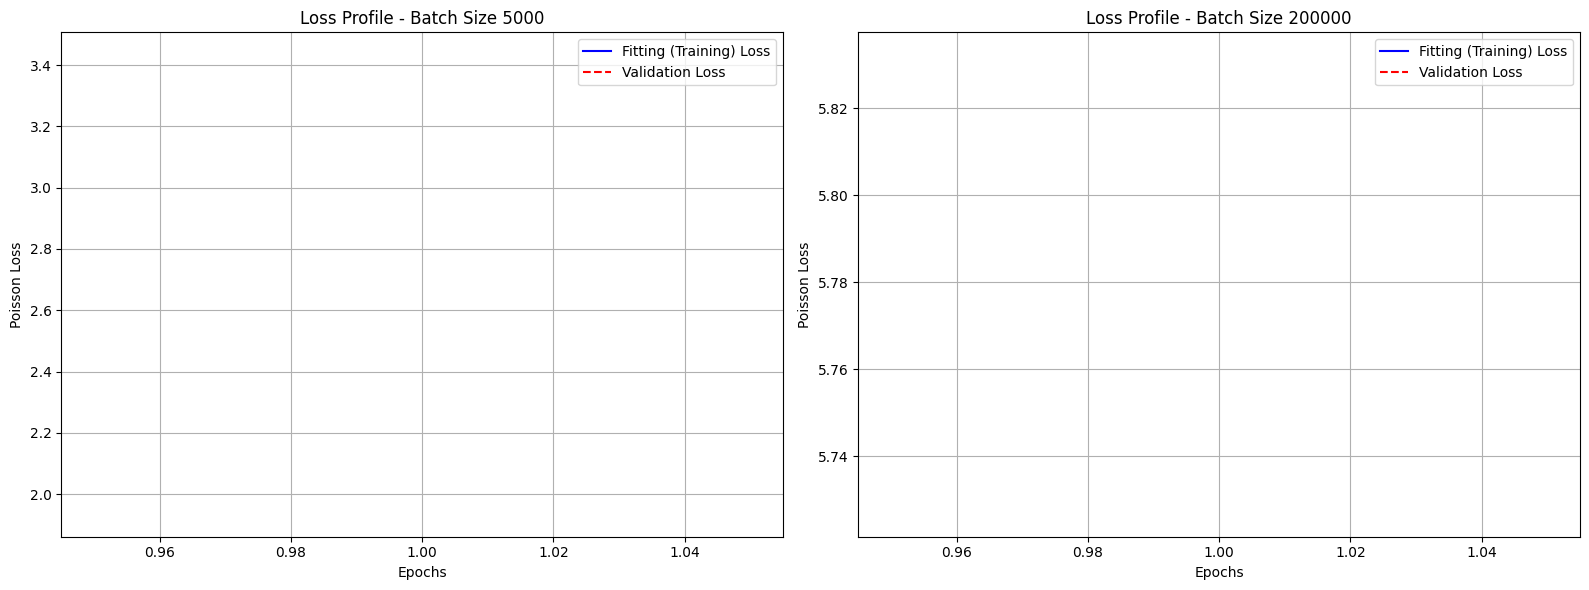

In [19]:
# Find the models with split=0.1, constructor='glm_keras', name='glm_keras_trained'
# and batch_size in [5000, 200000]
plot_models = {}
for m in model_list:
    if (
        getattr(m, 'constructor', None) == 'glm_keras'
        and getattr(m, 'name', None) == 'glm_keras_trained'
        and getattr(m, 'split', None) == 0.1
        and getattr(m, 'batch_size', None) in [5000, 200000]
        and hasattr(m, 'history')
    ):
        plot_models[m.batch_size] = m

# Create the plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

for ax, batch_size in zip(axes, [5000, 200000]):
    if batch_size in plot_models:
        m = plot_models[batch_size]
        history = m.history.history
        epochs = range(1, len(history['loss']) + 1)

        ax.plot(epochs, history['loss'], 'b-', label='Fitting (Training) Loss')
        if 'val_loss' in history:
            ax.plot(epochs, history['val_loss'], 'r--', label='Validation Loss')

        ax.set_title(f'Loss Profile - Batch Size {batch_size}')
        ax.set_xlabel('Epochs')
        ax.set_ylabel('Poisson Loss')
        ax.legend()
        ax.grid(True)
    else:
        ax.text(0.5, 0.5, f'Model for batch size {batch_size} not found',
                horizontalalignment='center', verticalalignment='center')

plt.tight_layout()
plt.show()

### 3.5 Relationship between Poisson loss and deviance
Verify that the poisson deviance used by keras and the scaled deviance used by AI for actuaries are indeed an affine transform of each other

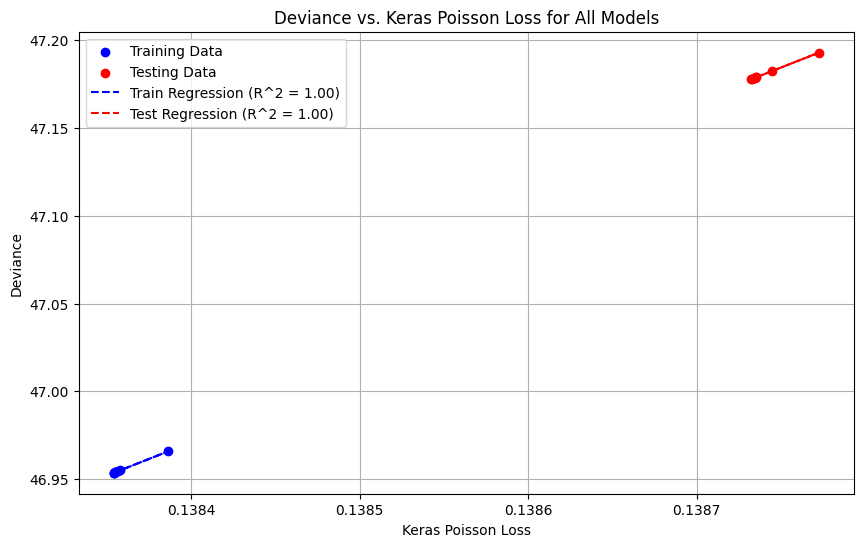

In [20]:
train_deviance_values = []
train_keras_poisson_values = []
test_deviance_values = []
test_keras_poisson_values = []

for model_info in model_list:
    if hasattr(model_info, 'train') and hasattr(model_info.train, 'deviance') and hasattr(model_info.train, 'keras_poisson') \
       and hasattr(model_info, 'test') and hasattr(model_info.test, 'deviance') and hasattr(model_info.test, 'keras_poisson'):


        if model_info.train.keras_poisson > 0.2: continue

        train_deviance_values.append(model_info.train.deviance)
        train_keras_poisson_values.append(model_info.train.keras_poisson)
        test_deviance_values.append(model_info.test.deviance)
        test_keras_poisson_values.append(model_info.test.keras_poisson)

plt.figure(figsize=(10, 6))
plt.scatter(train_keras_poisson_values, train_deviance_values, color='blue', label='Training Data')
plt.scatter(test_keras_poisson_values, test_deviance_values, color='red', label='Testing Data')

# Calculate and plot regression line for training data
if len(train_keras_poisson_values) > 1:
    slope_train, intercept_train, r_value_train, p_value_train, std_err_train = stats.linregress(train_keras_poisson_values, train_deviance_values)
    plt.plot(train_keras_poisson_values, intercept_train + slope_train * np.array(train_keras_poisson_values), color='blue', linestyle='--', label=f'Train Regression (R^2 = {r_value_train**2:.2f})')

# Calculate and plot regression line for testing data
if len(test_keras_poisson_values) > 1:
    slope_test, intercept_test, r_value_test, p_value_test, std_err_test = stats.linregress(test_keras_poisson_values, test_deviance_values)
    plt.plot(test_keras_poisson_values, intercept_test + slope_test * np.array(test_keras_poisson_values), color='red', linestyle='--', label=f'Test Regression (R^2 = {r_value_test**2:.2f})')

plt.xlabel('Keras Poisson Loss')
plt.ylabel('Deviance')
plt.title('Deviance vs. Keras Poisson Loss for All Models')
plt.legend()
plt.grid(True)
plt.show()

In [21]:
def write_latex_tables():
  names = {
    "batch_size": "Batch size",
    "epochs": "Epochs",
    "split": "Validation",
    "regularizer": "Regularizer",
    "train_deviance": "Train dev.",
    "train_relative_scoring": "Train O/E",
    "test_deviance": "Test dev.",
    "test_relative_scoring": "Test O/E",
  }

  # Only keep keys that are actually present in results_df
  available_keys = [k for k in names.keys() if k in results_df.columns]
  rename_dict = {k: names[k] for k in available_keys}
  format_dict = {
    "Batch size": "{:.0f}",
    "Epochs": "{:.0f}",
    "Validation": "{:.1f}",
    "Regularizer": "{:.4f}",
    "Train dev.": "{:.3f}",
    "Train O/E": "{:.4f}",
    "Test dev.": "{:.3f}",
    "Test O/E": "{:.4f}",
  }
  # Filter the format dictionary to only include renamed columns that are present
  active_formats = {k: v for k, v in format_dict.items() if k in rename_dict.values()}

  # MLE-initialised
  table_mle = (
      results_df.loc[results_df["initializer"] == "glm1", available_keys]
      .sort_values([col for col in ["batch_size", "split"] if col in available_keys], na_position="first")
  ).rename(columns=rename_dict)

  latex_mle = (
    table_mle.style
    .format(active_formats, na_rep="")
    .hide(axis="index")
    .to_latex(
        hrules=True,
        caption="Drift away from MLE",
        label="tab:glm_keras_mle_init",
    )
  )

  # Randomly initialised
  table_random = (
      results_df.loc[
          (results_df["initializer"].isna()) | (results_df["initializer"] == "None") | (results_df.get("fnn_initializer", pd.Series(dtype=object)).isna()) | (results_df.get("fnn_initializer", None) == "zero") | (results_df.get("fnn_initializer", None) == "mean"), available_keys
      ]
      .sort_values([col for col in ["batch_size", "split"] if col in available_keys], na_position="first")
  ).rename(columns=rename_dict)

  latex_rnd = (
    table_random.style
    .format(active_formats, na_rep="")
    .hide(axis="index")
    .to_latex(
        hrules=True,
        caption="Comparison of GLM estimation procedures.",
        label="tab:glm_keras_comparison",
    )
  )

  filename = "glm_keras_mle_init.tex"
  with open(filename, "w", encoding="utf-8") as f:
    f.write(latex_mle)
  files.download(filename)

  filename = "glm_keras_comparison.tex"
  with open(filename, "w", encoding="utf-8") as f:
    f.write(latex_rnd)
  files.download(filename)

write_latex_tables()

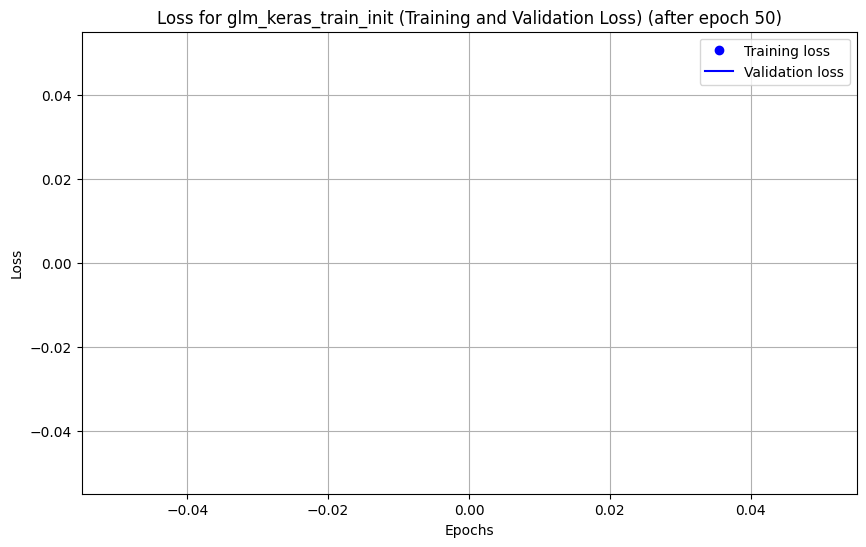

In [22]:
model_to_plot = model_list[-1]

if hasattr(model_to_plot, 'history'):
    history = model_to_plot.history.history
    epochs_to_skip = 50

    plt.figure(figsize=(10, 6))

    # Extract and plot training loss
    loss = history['loss'][epochs_to_skip:]
    epochs = range(epochs_to_skip + 1, len(history['loss']) + 1)
    plt.plot(epochs, loss, 'bo', label='Training loss')
    title_suffix = ""

    # Conditionally extract and plot validation loss
    if 'val_loss' in history:
        val_loss = history['val_loss'][epochs_to_skip:]
        plt.plot(epochs, val_loss, 'b', label='Validation loss')
        title_suffix = "(Training and Validation Loss)"
    else:
        title_suffix = "(Training Loss Only)"

    plt.title(f'Loss for {model_to_plot.name} {title_suffix} (after epoch {epochs_to_skip})')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print(f"Model {model_to_plot.name} does not have a history object to plot.")

## 4. FNN and frozen CANN benchmarks


### 4.1 Neural feature construction
The model is defined in two steps: a FNN taken from AI for actuaries which will be reused in the mixed regularized model.

Of particular note are the input preparation using scaler and embedding.


In [23]:
def clip_and_scale(upper):
    pipe = Pipeline(
        steps=[
            ("clip", FunctionTransformer(lambda x: np.clip(x, a_min=0, a_max=upper))),
            ("scale", StandardScaler()),
        ]
    )
    return pipe


density = Pipeline(
    steps=[
        ("log", FunctionTransformer(lambda x: np.log(x).round(2))),
        ("scale", StandardScaler()),
    ]
)

area = Pipeline(
    steps=[
        ("encode", OrdinalEncoder()),
        ("scale", StandardScaler()),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "scale",
            clip_and_scale([20, 90, 150, 15]),
            ["VehAge", "DrivAge", "BonusMalus", "VehPower"],
        ),
        ("area", area, ["Area"]),
        ("density", density, ["Density"]),
        ("veh_gas", FunctionTransformer(lambda x: x == "Diesel"), ["VehGas"]),
        ("veh_brand", OrdinalEncoder(), ["VehBrand", "Region"]),
    ],
    verbose_feature_names_out=False,
)

mtpl.fnn_data = SimpleNamespace(
  X_learn = preprocessor.fit_transform(mtpl.raw_data.training_data_raw),
  X_test  = preprocessor.transform(mtpl.raw_data.testing_data_raw),
  y_learn = mtpl.raw_data.training_data_raw.ClaimNb,
  v_learn = glm1.train.prediction,
  y_test  = mtpl.raw_data.testing_data_raw.ClaimNb,
  v_test  = glm1.test.prediction,
)

### 4.2 FNN architecture

In [24]:
# define FNN with entity embedding and three hidden layers
def create_fnn_linear_predictor(n_features, hidden_layers, kk, bb, kernel_regularizer, final_bias, freeze_hidden=False):
    design_input = keras.layers.Input(shape=(n_features,))

    # Extract brand and region features (last two columns)
    brand_input = keras.layers.Lambda(lambda x: x[:, -2:-1])(design_input)
    region_input = keras.layers.Lambda(lambda x: x[:, -1:])(design_input)

    # Embedding layers
    brand_embed = keras.layers.Embedding(input_dim=kk[0], output_dim=bb[0], trainable=not freeze_hidden)(brand_input)
    brand_embed = keras.layers.Flatten()(brand_embed)

    region_embed = keras.layers.Embedding(input_dim=kk[1], output_dim=bb[1], trainable=not freeze_hidden)(region_input)
    region_embed = keras.layers.Flatten()(region_embed)

    # Continuous features (all except last two columns)
    continuous_features = keras.layers.Lambda(lambda x: x[:, :-2])(design_input)

    # Concatenate all features
    x = keras.layers.Concatenate()([continuous_features, brand_embed, region_embed])

    # build the network
    for q in hidden_layers:
        x = keras.layers.Dense(q, activation="tanh", trainable=not freeze_hidden, kernel_regularizer=kernel_regularizer)(x)

    linear_predictor = keras.layers.Dense(1, activation="linear", name='fnn_linear_predictor', kernel_regularizer=kernel_regularizer, use_bias=final_bias)(x)

    return linear_predictor, design_input


def create_fnn(seed, n_features, hidden_layers, kk, bb, kernel_regularizer):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    glm_prediction_input = keras.layers.Input(shape=(1,))

    linear_predictor, design_input  = create_fnn_linear_predictor(n_features, hidden_layers, kk, bb, kernel_regularizer, final_bias=True)
    correction = keras.layers.Activation("exponential")(linear_predictor)

    output = keras.layers.Multiply()([correction, glm_prediction_input])

    model = keras.Model(inputs=[design_input, glm_prediction_input], outputs=output)

    return model

### 4.3 CANN construction and GLM reproduction
The cann constructor can be parametrized to use GLM predictions or to run without, thus allowing to evaluate the difference between the FNN learning the full function or only a correction to the GLM.

In [25]:
def cann(name, data, initializer, use_glm, split, batch_size, epochs, keep_best, description, seed=1234):
    tf.keras.utils.set_random_seed(seed)

    if use_glm:
      glm_factor = 1
    else:
      glm_factor = 0

    model_info = SimpleNamespace(
        name=name,
        description=description,
        constructor='cann',
        initializer= initializer if initializer else "None",
        split=split,
        batch_size=batch_size,
        epochs=epochs,
        keep_best=keep_best,
        seed=seed,
        regularizer = 'none',
        train = SimpleNamespace(target = data.fnn_data.y_learn,
                            exposure = data.glm_data.training_data['Exposure'],
                            input = (
                                data.fnn_data.X_learn,
                                data.fnn_data.v_learn * glm_factor + (1-glm_factor))),
        test = SimpleNamespace(target = data.fnn_data.y_test,
                              exposure = data.glm_data.testing_data['Exposure'],
                              input = (
                                  data.fnn_data.X_test,
                                  data.fnn_data.v_test * glm_factor + (1-glm_factor))),
    )


    HIDDEN = [20, 15, 10]
    M_FEAT = data.fnn_data.X_learn.shape[1]
    KK = [len(data.raw_data.training_data_raw['VehBrand'].unique()), len(data.raw_data.training_data_raw['Region'].unique())]
    BB  = [2,2]


    # Create model with three hidden layers
    model_info.model = create_fnn(seed, M_FEAT, HIDDEN, KK, BB, None)

    if initializer == 'zero':
      w0 = model_info.model.get_weights()
      w0[-2] *= 0
      w0[-1] *= 0
      model_info.model.set_weights(w0)

    elif initializer == 'mean':
      w0 = model_info.model.get_weights()
      w0[-2] *= 0
      w0[-1][...] = np.log(model_info.train.target.sum() / model_info.train.exposure.sum())
      model_info.model.set_weights(w0)



    if epochs is not None:
      callbacks = [OneLineProgress()]
      if keep_best:
        callbacks.append(keras.callbacks.EarlyStopping(
          monitor="val_loss" if split else "loss",
          patience=epochs,          # effectively prevents early stopping
          restore_best_weights=True,
        ))

      model_info.model.compile(loss="poisson", optimizer="nadam")
      model_info.history = model_info.model.fit(
        model_info.train.input,
        model_info.train.target / model_info.train.exposure,
        sample_weight=model_info.train.exposure,
        validation_split=split,
        batch_size=batch_size,
        epochs=effective_epochs(epochs),
        verbose=0,
        callbacks=callbacks,
      )
    model_info.train.prediction = model_info.model(model_info.train.input, training=False).numpy()
    model_info.test.prediction = model_info.model(model_info.test.input, training=False).numpy()
    calculate_deviance(model_info)
    return model_info


### 4.4 Benchmark training

In [26]:
model_list.append(cann('cann_glm_only', mtpl, 'zero', True, None, None, None, None, 'reproduce GLM with cann setup'))

Training Deviance = 46.954 Keras Poisson = 0.13835  Total Actual Claims: 23738.00  Total Predicted Claims: 23738.00  Relative Scoring (Actual / Predicted): 1.0000
Testing Deviance = 47.179 Keras Poisson = 0.13874  Total Actual Claims: 2645.00  Total Predicted Claims: 2650.74  Relative Scoring (Actual / Predicted): 0.9978


In [27]:
model_list.append(cann('cann', mtpl, None, True, 0.1, 5000, 200, True, 'cann with fixed glm offset'))

Epoch 1/1 - loss: 0.136322  - val_loss: 0.134198
Training Deviance = 45.928 Keras Poisson = 0.13564  Total Actual Claims: 23738.00  Total Predicted Claims: 23270.06  Relative Scoring (Actual / Predicted): 1.0201
Testing Deviance = 45.883 Keras Poisson = 0.13530  Total Actual Claims: 2645.00  Total Predicted Claims: 2604.12  Relative Scoring (Actual / Predicted): 1.0157


In [28]:
model_list.append(cann('cann_no_glm', mtpl, None, False, 0.1, 5000, 200, True, 'cann with fnn only'))

Epoch 1/1 - loss: 0.193715  - val_loss: 0.136993
Training Deviance = 46.878 Keras Poisson = 0.13815  Total Actual Claims: 23738.00  Total Predicted Claims: 24018.64  Relative Scoring (Actual / Predicted): 0.9883
Testing Deviance = 46.834 Keras Poisson = 0.13782  Total Actual Claims: 2645.00  Total Predicted Claims: 2684.83  Relative Scoring (Actual / Predicted): 0.9852


In [29]:
model_list.append(cann('cann_no_glm_mean_init', mtpl, 'mean', False, 0.1, 5000, 200, True, 'cann with fnn only'))

Epoch 1/1 - loss: 0.137878  - val_loss: 0.134507
Training Deviance = 46.042 Keras Poisson = 0.13595  Total Actual Claims: 23738.00  Total Predicted Claims: 23133.00  Relative Scoring (Actual / Predicted): 1.0262
Testing Deviance = 45.991 Keras Poisson = 0.13559  Total Actual Claims: 2645.00  Total Predicted Claims: 2584.19  Relative Scoring (Actual / Predicted): 1.0235


### 4.5 Training-history comparison

In [30]:
def plot_history(model_to_plot, epochs_to_skip = 50):
    history = model_to_plot.history.history


    plt.figure(figsize=(10, 6))

    # Extract and plot training loss
    loss = history['loss'][epochs_to_skip:]
    epochs = range(epochs_to_skip + 1, len(history['loss']) + 1)
    plt.plot(epochs, loss, 'bo', label='Training loss')
    title_suffix = ""

    # Conditionally extract and plot validation loss
    if 'val_loss' in history:
        val_loss = history['val_loss'][epochs_to_skip:]
        plt.plot(epochs, val_loss, 'b', label='Validation loss')
        title_suffix = "(Training and Validation Loss)"
    else:
        title_suffix = "(Training Loss Only)"

    plt.title(f'Loss for {model_to_plot.name} {title_suffix} (after epoch {epochs_to_skip})')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

In [31]:
def plot_history2(model1, model2, epochs_to_skip=50):
    plt.figure(figsize=(12, 7))

    # Plot history for Model 1 (blue)
    if hasattr(model1, 'history'):
        history1 = model1.history.history
        loss1 = history1['loss'][epochs_to_skip:]
        epochs1 = range(epochs_to_skip + 1, len(history1['loss']) + 1)
        plt.plot(epochs1, loss1, 'bo-', label=f'{model1.name} Training loss')

        if 'val_loss' in history1:
            val_loss1 = history1['val_loss'][epochs_to_skip:]
            plt.plot(epochs1, val_loss1, 'b--', label=f'{model1.name} Validation loss')

    # Plot history for Model 2 (red)
    if hasattr(model2, 'history'):
        history2 = model2.history.history
        loss2 = history2['loss'][epochs_to_skip:]
        epochs2 = range(epochs_to_skip + 1, len(history2['loss']) + 1)
        plt.plot(epochs2, loss2, 'ro-', label=f'{model2.name} Training loss')

        if 'val_loss' in history2:
            val_loss2 = history2['val_loss'][epochs_to_skip:]
            plt.plot(epochs2, val_loss2, 'r--', label=f'{model2.name} Validation loss')

    plt.title(f'Training History Comparison (after epoch {epochs_to_skip})')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

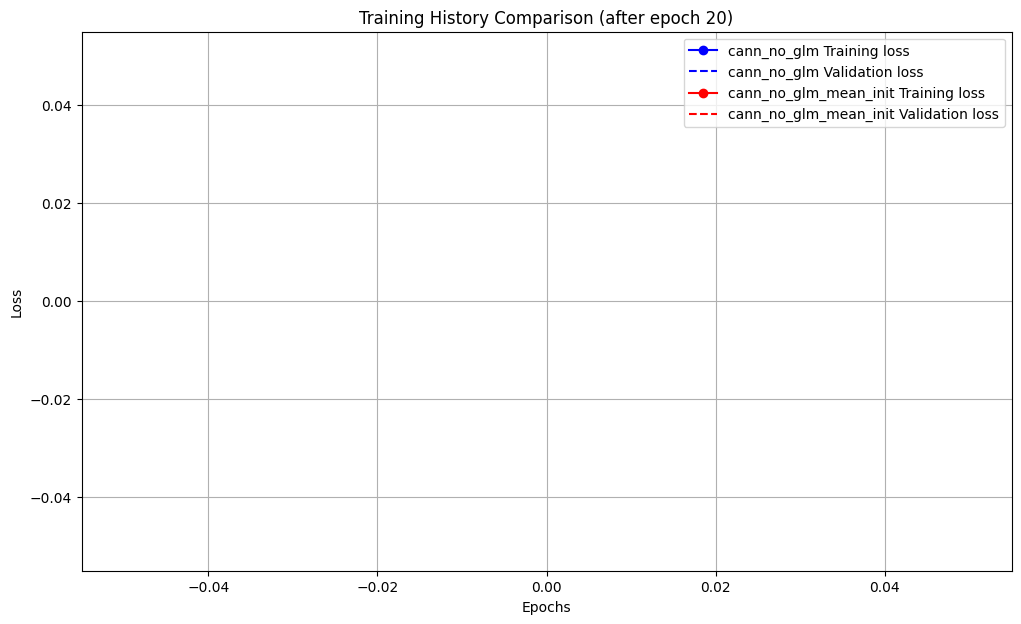

In [32]:
plot_history2(model_list[-2], model_list[-1], 20)

## 5. Jointly trained regularized hybrid


### 5.1 Architecture and regularization

In [33]:
def create_mixed(seed, n_features, hidden_layers, kk, bb, kernel_regularizer, n_glm_features, glm_initializer):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    fnn_linear_predictor, design_input = create_fnn_linear_predictor(n_features, hidden_layers, kk, bb, kernel_regularizer, final_bias=False)
    glm_linear_predictor, glm_input = create_glm_linear_predictor(n_glm_features, glm_initializer)

    linear_predictor = keras.layers.Add()([fnn_linear_predictor, glm_linear_predictor])

    output = keras.layers.Activation("exponential")(linear_predictor)

    model = keras.Model(inputs=[design_input, glm_input], outputs=output)

    return model

def regularized_glm_nn(name, data, fnn_initializer, glm_initializer, split, batch_size, epochs, keep_best, reg, description, seed=1234):
    tf.keras.utils.set_random_seed(seed)

    model_info = SimpleNamespace(
        name=name,
        description=description,
        constructor='regularized_glm_nn',
        fnn_initializer=fnn_initializer,
        glm_initializer=glm_initializer,
        split=split,
        batch_size=batch_size,
        epochs=epochs,
        keep_best=keep_best,
        seed=seed,
        regularizer = str(reg),
        train = SimpleNamespace(target = data.fnn_data.y_learn,
                            exposure = data.glm_data.training_data['Exposure'],
                            input = (data.fnn_data.X_learn, data.glm_data.training_data_1h)),
        test = SimpleNamespace(target = data.fnn_data.y_test,
                          exposure = data.glm_data.testing_data['Exposure'],
                          input = (data.fnn_data.X_test, data.glm_data.testing_data_1h)),
    )

    l2_reg = keras.regularizers.L2(reg)

    HIDDEN = [20, 15, 10]
    M_FEAT = data.fnn_data.X_learn.shape[1]
    KK = [len(data.raw_data.training_data_raw['VehBrand'].unique()), len(data.raw_data.training_data_raw['Region'].unique())]
    BB  = [2,2]

    glm_init = None
    if glm_initializer is not None:
      glm_init = glm_to_keras(glm_initializer.results.params, data.glm_data.training_data_1h.columns)

    n_glm_features = data.glm_data.training_data_1h.shape[1]

    # Pass glm parameters to create_mixed
    model_info.model = create_mixed(seed, M_FEAT, HIDDEN, KK, BB, l2_reg, n_glm_features, glm_init)

    if fnn_initializer == 'zero':
      fnn_layer = model_info.model.get_layer("fnn_linear_predictor")
      w0 = fnn_layer.get_weights()
      #w0[-2] *= 0
      #w0[-1] *= 0
      fnn_layer.set_weights([np.zeros_like(w) for w in w0])

    if epochs is not None:
      callbacks = [OneLineProgress()]
      if keep_best:
        callbacks.append(keras.callbacks.EarlyStopping(
          monitor="val_loss" if split else "loss",
          patience=epochs,          # effectively prevents early stopping
          restore_best_weights=True,
        ))

      model_info.model.compile(loss="poisson", optimizer="nadam")
      model_info.history = model_info.model.fit(
        model_info.train.input,
        model_info.train.target / model_info.train.exposure,
        sample_weight=model_info.train.exposure,
        validation_split=split,
        batch_size=batch_size,
        epochs=effective_epochs(epochs),
        verbose=0,
        callbacks=callbacks,
      )
    model_info.train.prediction = model_info.model(model_info.train.input, training=False).numpy()
    model_info.test.prediction = model_info.model(model_info.test.input, training=False).numpy()
    calculate_deviance(model_info)
    return model_info

### 5.2 Initialisation and GLM reproduction
Check wether GLM is reproduced if FNN is set to zero

In [34]:
model_list.append(regularized_glm_nn('rglnn_no_train', mtpl, 'zero', glm1, 0.1, 5000, None, True, 0.1, 'glm initialized rglnn'))

Training Deviance = 46.954 Keras Poisson = 0.13835  Total Actual Claims: 23738.00  Total Predicted Claims: 23738.00  Relative Scoring (Actual / Predicted): 1.0000
Testing Deviance = 47.179 Keras Poisson = 0.13874  Total Actual Claims: 2645.00  Total Predicted Claims: 2650.74  Relative Scoring (Actual / Predicted): 0.9978


### 5.3 Regularization parameter sweep
Study the behaviour of the hybrid model under different values for the regularization penalty

In [35]:
for reg in [0.0, 1e-6, 1e-5, 1e-4, 2e-4, 5e-4, 1e-3, 0.0012, 0.0014, 0.0016, 0.00164, 0.00168, 0.00172, 0.00176, 0.00177, 0.00178, 0.00179, 0.0018, 2e-3, 5e-3, 1e-2, 0.1, 1]:
  model_list.append(regularized_glm_nn('rglnn', mtpl, 'zero', glm1, 0.1, 50000, 200, True, reg, f'regularized with L2={reg}'))

Epoch 1/1 - loss: 0.138406  - val_loss: 0.137252
Training Deviance = 46.892 Keras Poisson = 0.13819  Total Actual Claims: 23738.00  Total Predicted Claims: 23668.91  Relative Scoring (Actual / Predicted): 1.0029
Testing Deviance = 47.110 Keras Poisson = 0.13855  Total Actual Claims: 2645.00  Total Predicted Claims: 2643.10  Relative Scoring (Actual / Predicted): 1.0007
Epoch 1/1 - loss: 0.138451  - val_loss: 0.137298
Training Deviance = 46.893 Keras Poisson = 0.13819  Total Actual Claims: 23738.00  Total Predicted Claims: 23669.76  Relative Scoring (Actual / Predicted): 1.0029
Testing Deviance = 47.111 Keras Poisson = 0.13856  Total Actual Claims: 2645.00  Total Predicted Claims: 2643.19  Relative Scoring (Actual / Predicted): 1.0007
Epoch 1/1 - loss: 0.138852  - val_loss: 0.137709
Training Deviance = 46.902 Keras Poisson = 0.13822  Total Actual Claims: 23738.00  Total Predicted Claims: 23675.24  Relative Scoring (Actual / Predicted): 1.0027
Testing Deviance = 47.120 Keras Poisson = 0.

## 6. Results and structural diagnostics


In [36]:
results_data = []

for model_info in model_list:
    train_actual_claims = np.asarray(model_info.train.target).ravel()
    train_exposure = np.asarray(model_info.train.exposure).ravel()
    train_predicted_rates = np.asarray(model_info.train.prediction).ravel()
    train_predicted_claims = train_predicted_rates * train_exposure
    train_relative_scoring = train_actual_claims.sum() / train_predicted_claims.sum()

    test_actual_claims = np.asarray(model_info.test.target).ravel()
    test_exposure = np.asarray(model_info.test.exposure).ravel()
    test_predicted_rates = np.asarray(model_info.test.prediction).ravel()
    test_predicted_claims = test_predicted_rates * test_exposure
    test_relative_scoring = test_actual_claims.sum() / test_predicted_claims.sum()

    results_data.append({
        'name': getattr(model_info, 'name', None),
        'initializer': getattr(model_info, 'initializer', None),
        'fnn_initializer': getattr(model_info, 'fnn_initializer', None),
        'glm_initializer': getattr(getattr(model_info, 'glm_initializer', None), 'name', None),
        'batch_size': getattr(model_info, 'batch_size', None),
        'epochs': getattr(model_info, 'epochs', None),
        'keep_best': getattr(model_info, 'keep_best', None),
        'split': getattr(model_info, 'split', None),
        'regularizer': getattr(model_info, 'regularizer', None),
        'train_deviance': getattr(model_info.train, 'deviance', None),
        'train_relative_scoring': train_relative_scoring,
        'test_deviance': getattr(model_info.test, 'deviance', None),
        'test_relative_scoring': test_relative_scoring
    })

results_df = pd.DataFrame(results_data)
display(results_df)

,name,initializer,fnn_initializer,glm_initializer,batch_size,epochs,keep_best,split,regularizer,train_deviance,train_relative_scoring,test_deviance,test_relative_scoring
0,glm1,None,None,None,NaN,NaN,None,NaN,None,46.953720,1.000000,47.178625,0.997834
1,glm_keras_control,glm1,None,None,NaN,NaN,False,NaN,None,46.953720,1.000000,47.178625,0.997834
2,glm_keras_trained,None,None,None,5000.0,200.0,True,NaN,None,659.376661,0.021600,660.993031,0.021537
3,glm_keras_train_init,glm1,None,None,5000.0,20.0,False,NaN,None,46.955148,1.013199,47.182224,1.011035
4,glm_keras_trained,None,None,None,5000.0,200.0,True,0.1,None,725.020102,0.019668,726.749805,0.019611
5,glm_keras_train_init,glm1,None,None,5000.0,20.0,False,0.1,None,46.965811,1.039506,47.192697,1.037321
6,glm_keras_trained,None,None,None,50000.0,2000.0,True,NaN,None,1933.718824,0.007473,1936.842870,0.007454
7,glm_keras_train_init,glm1,None,None,50000.0,200.0,False,NaN,None,46.953860,1.004022,47.177694,1.001850
8,glm_keras_trained,None,None,None,50000.0,2000.0,True,0.1,None,1978.637526,0.007305,1981.794196,0.007286
9,glm_keras_train_init,glm1,None,None,50000.0,200.0,False,0.1,None,46.953732,1.000798,47.178491,0.998630


### 6.1 Predictive performance and calibration

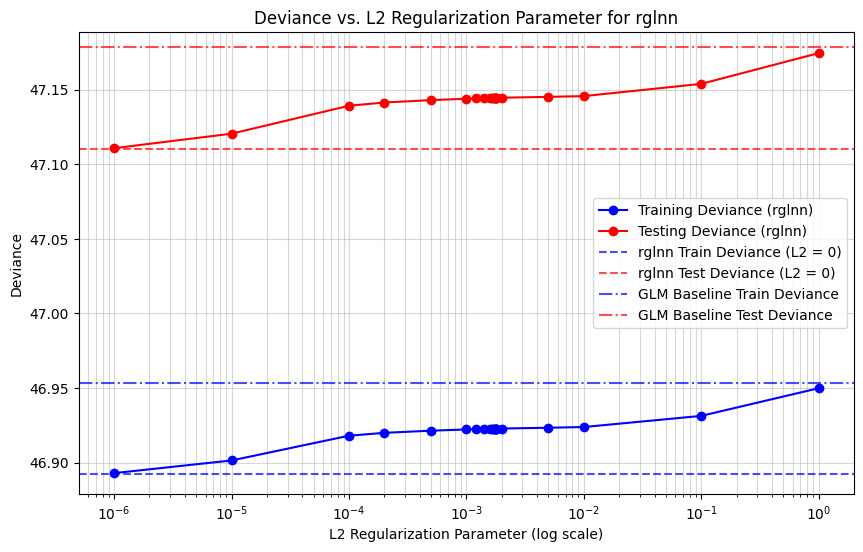

In [37]:
# Filter results to get the rglnn models with non-null numeric regularizers
reg_models = results_df[results_df['name'] == 'rglnn'].copy()
reg_models['regularizer'] = pd.to_numeric(reg_models['regularizer'], errors='coerce')
reg_models = reg_models.dropna(subset=['regularizer']).sort_values('regularizer')

# Separate zero regularization for plotting on log scale
zero_reg = reg_models[reg_models['regularizer'] == 0.0]
non_zero_reg = reg_models[reg_models['regularizer'] > 0.0]

plt.figure(figsize=(10, 6))

# Plot non-zero regularization values on a log scale
plt.plot(non_zero_reg['regularizer'], non_zero_reg['train_deviance'], 'bo-', label='Training Deviance (rglnn)')
plt.plot(non_zero_reg['regularizer'], non_zero_reg['test_deviance'], 'ro-', label='Testing Deviance (rglnn)')

# Highlight the zero regularization case if it exists
if not zero_reg.empty:
    plt.axhline(y=zero_reg['train_deviance'].values[0], color='blue', linestyle='--', alpha=0.7, label='rglnn Train Deviance (L2 = 0)')
    plt.axhline(y=zero_reg['test_deviance'].values[0], color='red', linestyle='--', alpha=0.7, label='rglnn Test Deviance (L2 = 0)')

# Get the baseline GLM (glm1) deviances
glm1_row = results_df[results_df['name'] == 'glm1']
if not glm1_row.empty:
    glm1_train = glm1_row['train_deviance'].values[0]
    glm1_test = glm1_row['test_deviance'].values[0]
    plt.axhline(y=glm1_train, color='blue', linestyle='-.', alpha=0.7, label='GLM Baseline Train Deviance')
    plt.axhline(y=glm1_test, color='red', linestyle='-.', alpha=0.7, label='GLM Baseline Test Deviance')

plt.xscale('log')
plt.xlabel('L2 Regularization Parameter (log scale)')
plt.ylabel('Deviance')
plt.title('Deviance vs. L2 Regularization Parameter for rglnn')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.savefig('deviance_vs_reg.pdf')
files.download('deviance_vs_reg.pdf')
plt.show()

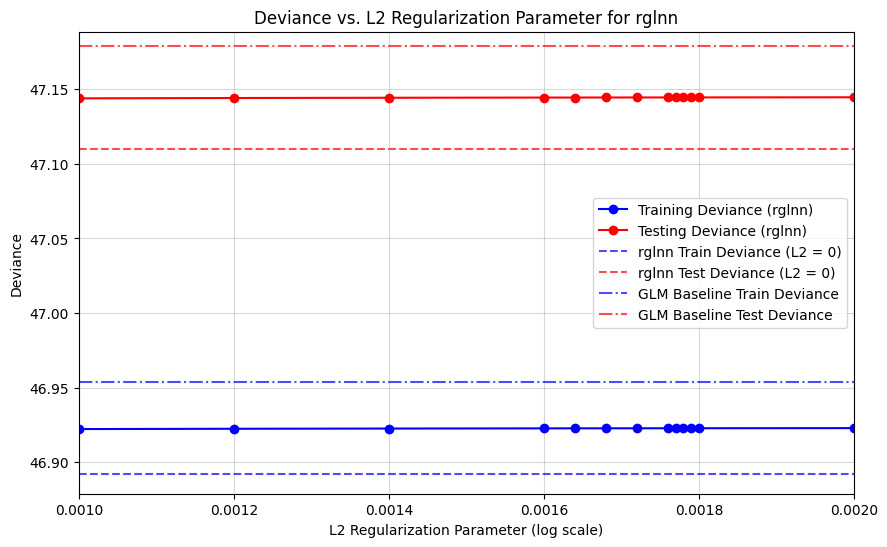

In [38]:
# Filter results to get the rglnn models with non-null numeric regularizers
reg_models = results_df[results_df['name'] == 'rglnn'].copy()
reg_models['regularizer'] = pd.to_numeric(reg_models['regularizer'], errors='coerce')
reg_models = reg_models.dropna(subset=['regularizer']).sort_values('regularizer')

# Separate zero regularization for plotting on log scale
zero_reg = reg_models[reg_models['regularizer'] == 0.0]
non_zero_reg = reg_models[reg_models['regularizer'] > 0.0]

plt.figure(figsize=(10, 6))

# Plot non-zero regularization values on a log scale
plt.plot(non_zero_reg['regularizer'], non_zero_reg['train_deviance'], 'bo-', label='Training Deviance (rglnn)')
plt.plot(non_zero_reg['regularizer'], non_zero_reg['test_deviance'], 'ro-', label='Testing Deviance (rglnn)')

# Highlight the zero regularization case if it exists
if not zero_reg.empty:
    plt.axhline(y=zero_reg['train_deviance'].values[0], color='blue', linestyle='--', alpha=0.7, label='rglnn Train Deviance (L2 = 0)')
    plt.axhline(y=zero_reg['test_deviance'].values[0], color='red', linestyle='--', alpha=0.7, label='rglnn Test Deviance (L2 = 0)')

# Get the baseline GLM (glm1) deviances
glm1_row = results_df[results_df['name'] == 'glm1']
if not glm1_row.empty:
    glm1_train = glm1_row['train_deviance'].values[0]
    glm1_test = glm1_row['test_deviance'].values[0]
    plt.axhline(y=glm1_train, color='blue', linestyle='-.', alpha=0.7, label='GLM Baseline Train Deviance')
    plt.axhline(y=glm1_test, color='red', linestyle='-.', alpha=0.7, label='GLM Baseline Test Deviance')

plt.xlim(1.0e-3, 2.0e-3)
plt.xlabel('L2 Regularization Parameter (log scale)')
plt.ylabel('Deviance')
plt.title('Deviance vs. L2 Regularization Parameter for rglnn')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

### 6.2 Regularization path and validation loss

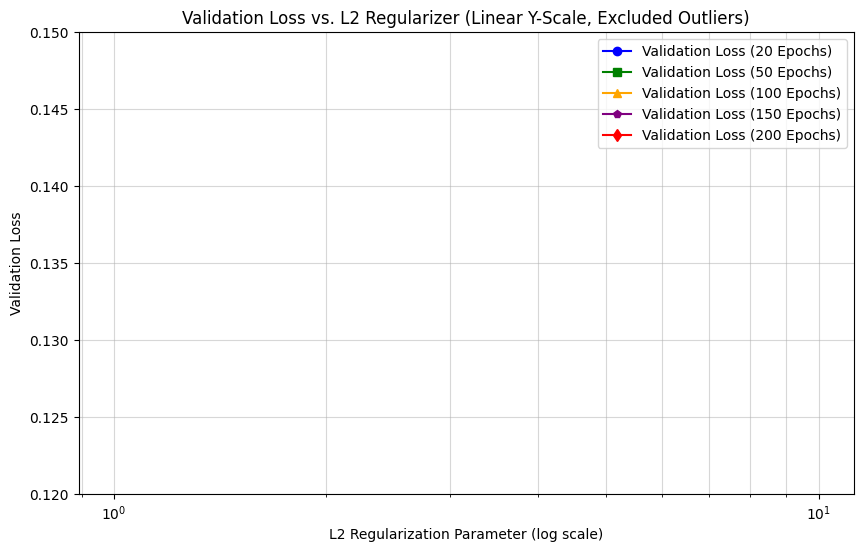

In [39]:
# Filter model_list to get the regularized GLM-NN (rglnn) models that have a training history
rglnn_models = [
    m for m in model_list
    if getattr(m, 'name', None) == 'rglnn'
    and hasattr(m, 'history')
    and 'val_loss' in m.history.history
]

# Collect the regularization parameter and validation loss at epochs 20, 50, 100, 150, 200
plot_data = []
for m in rglnn_models:
    reg_val = float(m.regularizer)

    # Exclude the lambda = 100 case entirely
    if reg_val == 100.0:
        continue

    history = m.history.history['val_loss']
    num_epochs = len(history)

    # Get validation losses safely
    val_20 = history[19] if num_epochs >= 20 else None
    val_50 = history[49] if num_epochs >= 50 else None
    val_100 = history[99] if num_epochs >= 100 else None
    val_150 = history[149] if num_epochs >= 150 else None
    val_200 = history[199] if num_epochs >= 200 else None

    # Specifically exclude epoch 20 validation loss for lambda = 0.1 and lambda = 1
    if reg_val in [0.1, 1.0]:
        val_20 = None

    plot_data.append({
        'regularizer': reg_val,
        'val_20': val_20,
        'val_50': val_50,
        'val_100': val_100,
        'val_150': val_150,
        'val_200': val_200
    })

# Create a DataFrame and sort by the L2 regularization parameter
df_plot = pd.DataFrame(plot_data).sort_values('regularizer')

# Separate zero vs non-zero for log scaling
non_zero_df = df_plot[df_plot['regularizer'] > 0]
zero_df = df_plot[df_plot['regularizer'] == 0]

plt.figure(figsize=(10, 6))

# Define the markers and colors for each epoch checkpoint
checkpoints = [
    ('val_20', '20 Epochs', 'o-', 'blue'),
    ('val_50', '50 Epochs', 's-', 'green'),
    ('val_100', '100 Epochs', '^-', 'orange'),
    ('val_150', '150 Epochs', 'p-', 'purple'),
    ('val_200', '200 Epochs', 'd-', 'red')
]

for col, label, style, color in checkpoints:
    # Mask out NaN values from non_zero_df so line segments connect correctly
    subset = non_zero_df.dropna(subset=[col])

    # Plot non-zero regularization values on a log x-scale
    plt.plot(subset['regularizer'], subset[col], style, color=color, label=f'Validation Loss ({label})')

    # Plot horizontal line for zero-regularization baseline
    if not zero_df.empty and zero_df[col].values[0] is not None:
        plt.axhline(y=zero_df[col].values[0], color=color, linestyle='--', alpha=0.5, label=f'L2=0 ({label})')

plt.xscale('log')
plt.ylim(0.12, 0.15)
plt.xlabel('L2 Regularization Parameter (log scale)')
plt.ylabel('Validation Loss')
plt.title('Validation Loss vs. L2 Regularizer (Linear Y-Scale, Excluded Outliers)')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

### 6.3 GLM coefficient paths

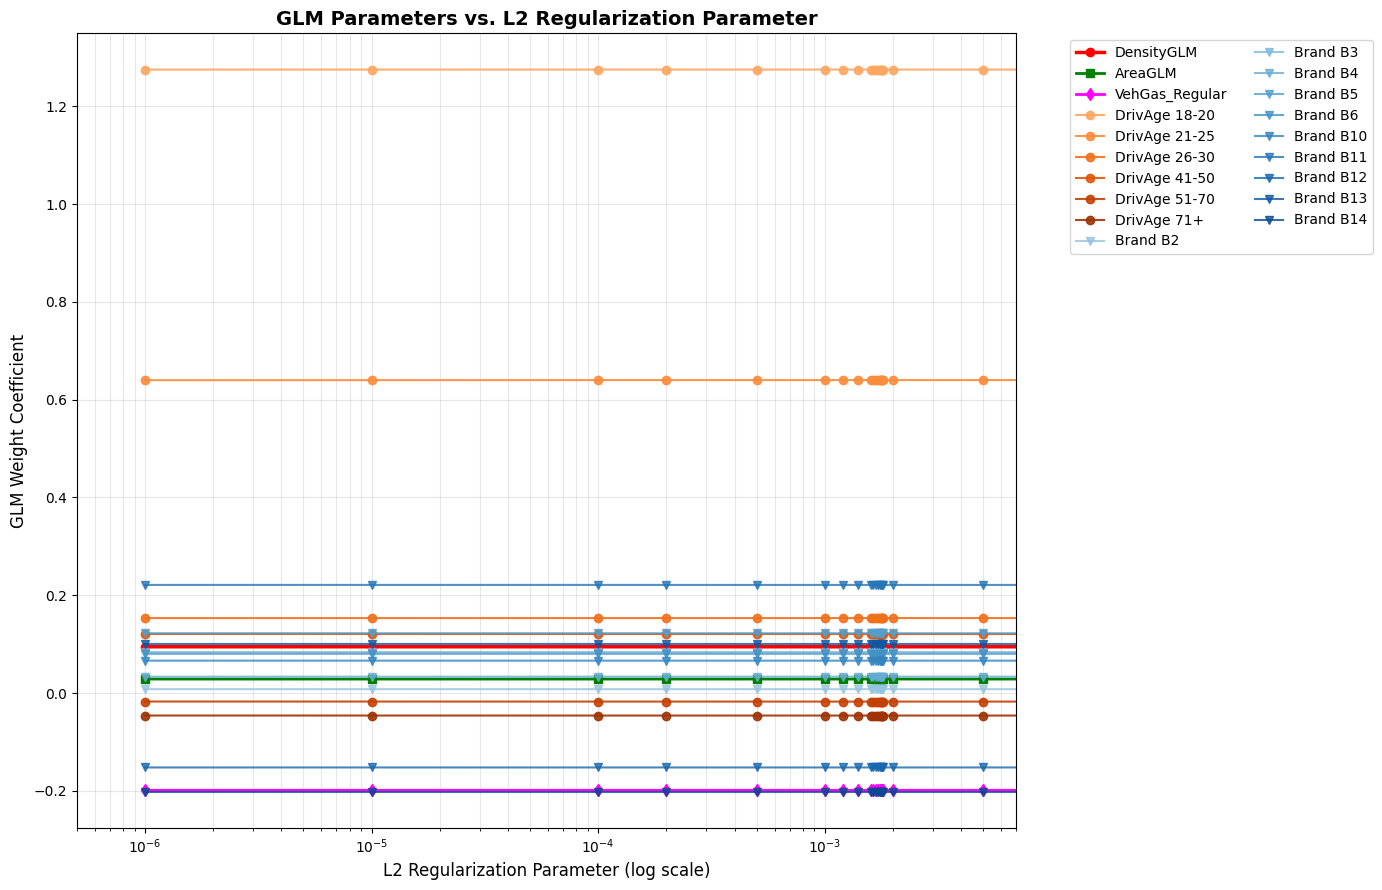

In [40]:
# Filter model_list to get the regularized GLM-NN (rglnn) models
rglnn_models = [
    m for m in model_list
    if getattr(m, 'name', None) == 'rglnn'
    and hasattr(m, 'model')
]

keras_columns = mtpl.glm_data.training_data_1h.columns.tolist()

# Grouping and finding indices
age_columns = [col for col in keras_columns if col.startswith('DrivAgeGLM_')]
brand_columns = [col for col in keras_columns if col.startswith('VehBrand_')]

density_idx = keras_columns.index('DensityGLM')
area_idx = keras_columns.index('AreaGLM')
gas_idx = keras_columns.index('VehGas_Regular')
age_indices = {col: keras_columns.index(col) for col in age_columns}
brand_indices = {col: keras_columns.index(col) for col in brand_columns}

param_history = []

for m in rglnn_models:
    reg_val = float(m.regularizer)
    glm_layer = m.model.get_layer('glm_linear_predictor')
    weights, bias = glm_layer.get_weights()

    entry = {
        'lambda': reg_val,
        'Intercept': bias[0],
        'DensityGLM': weights[density_idx, 0],
        'AreaGLM': weights[area_idx, 0],
        'VehGas_Regular': weights[gas_idx, 0]
    }
    for col, idx in age_indices.items():
        entry[col] = weights[idx, 0]
    for col, idx in brand_indices.items():
        entry[col] = weights[idx, 0]
    param_history.append(entry)

df_params = pd.DataFrame(param_history).sort_values('lambda')
non_zero_df = df_params[df_params['lambda'] > 0]

plt.figure(figsize=(14, 9))

# 1. Distinct standalone variables
#plt.plot(non_zero_df['lambda'], non_zero_df['Intercept'], 'o-', label='Intercept', color='black', linewidth=2.5)
plt.plot(non_zero_df['lambda'], non_zero_df['DensityGLM'], 'o-', label='DensityGLM', color='red', linewidth=2.5)
plt.plot(non_zero_df['lambda'], non_zero_df['AreaGLM'], 's-', label='AreaGLM', color='green', linewidth=2.0)
plt.plot(non_zero_df['lambda'], non_zero_df['VehGas_Regular'], 'd-', label='VehGas_Regular', color='magenta', linewidth=2.0)

# 2. Driver Age Category Trajectories (Shades of Orange/Red/Gold)
age_colors = plt.cm.Oranges(np.linspace(0.4, 0.9, len(age_columns)))
for i, col in enumerate(age_columns):
    label_name = col.replace('DrivAgeGLM_', 'DrivAge ')
    plt.plot(non_zero_df['lambda'], non_zero_df[col], 'o-', label=label_name, color=age_colors[i], alpha=0.9)

# 3. Vehicle Brand Category Trajectories (Shades of Blue/Cyan)
brand_colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(brand_columns)))
for i, col in enumerate(brand_columns):
    label_name = col.replace('VehBrand_', 'Brand ')
    plt.plot(non_zero_df['lambda'], non_zero_df[col], 'v-', label=label_name, color=brand_colors[i], alpha=0.8)

plt.xscale('log')
plt.xlim(5e-7,7e-3)
plt.xlabel('L2 Regularization Parameter (log scale)', fontsize=12)
plt.ylabel('GLM Weight Coefficient', fontsize=12)
plt.title('GLM Parameters vs. L2 Regularization Parameter', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)
plt.grid(True, which="both", ls="-", alpha=0.3)
plt.tight_layout()
plt.show()

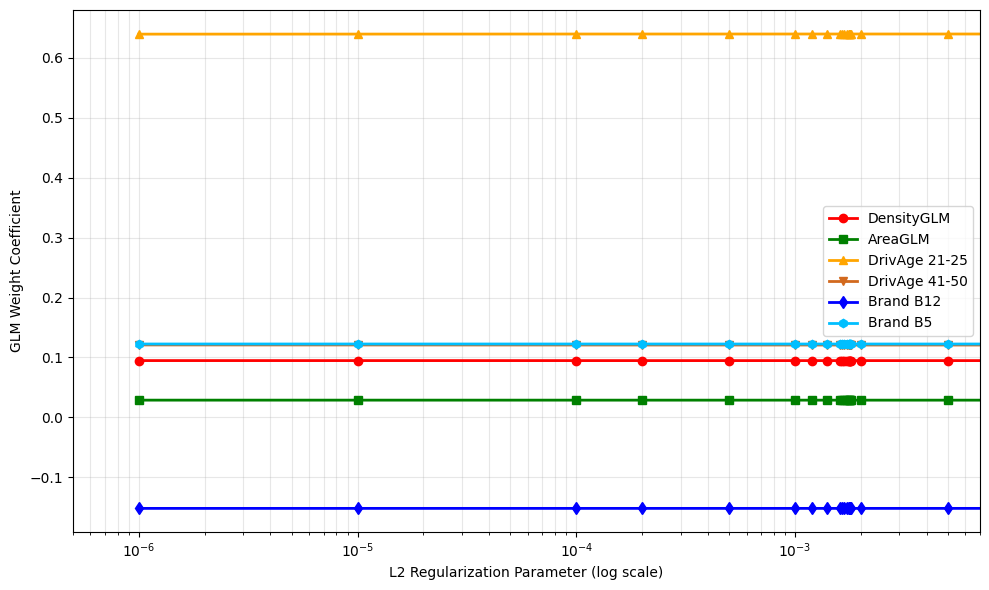

In [41]:
plt.figure(figsize=(10, 6))

# Filter to requested columns
requested_cols = {
    'DensityGLM': ('DensityGLM', 'o-', 'red'),
    'AreaGLM': ('AreaGLM', 's-', 'green'),
    'DrivAgeGLM_21-25': ('DrivAge 21-25', '^-', 'orange'),
    'DrivAgeGLM_41-50': ('DrivAge 41-50', 'v-', 'chocolate'),
    'VehBrand_B12': ('Brand B12', 'd-', 'blue'),
    'VehBrand_B5': ('Brand B5', 'h-', 'deepskyblue')
}

for col, (label, marker, color) in requested_cols.items():
    if col in non_zero_df.columns:
        plt.plot(non_zero_df['lambda'], non_zero_df[col], marker, label=label, color=color, linewidth=2.0)

plt.xscale('log')
plt.xlim(5e-7, 7e-3)
plt.xlabel('L2 Regularization Parameter (log scale)')
plt.ylabel('GLM Weight Coefficient')
#plt.title('Subset of GLM Parameters vs. L2 Regularization Parameter', fontsize=14, fontweight='bold')
plt.legend(loc='best')
plt.grid(True, which="both", ls="-", alpha=0.3)
plt.tight_layout()
plt.savefig('glmbeta_vs_reg.pdf')
files.download('glmbeta_vs_reg.pdf')
plt.show()

### 6.4 FNN correction statistics and distribution

In [42]:
def fnn_correction(model_info):
  intermediate_model = keras.Model(
      inputs=model_info.model.inputs,
      outputs=[
          model_info.model.get_layer("glm_linear_predictor").output,
          model_info.model.get_layer("fnn_linear_predictor").output,
          model_info.model.output,
      ]
  )

  glm_eta, fnn_eta, prediction = intermediate_model(model_info.train.input, training=False)

  f = fnn_eta.numpy().ravel()

  return f.mean(), f.std(), (f**2).mean()**0.5, f


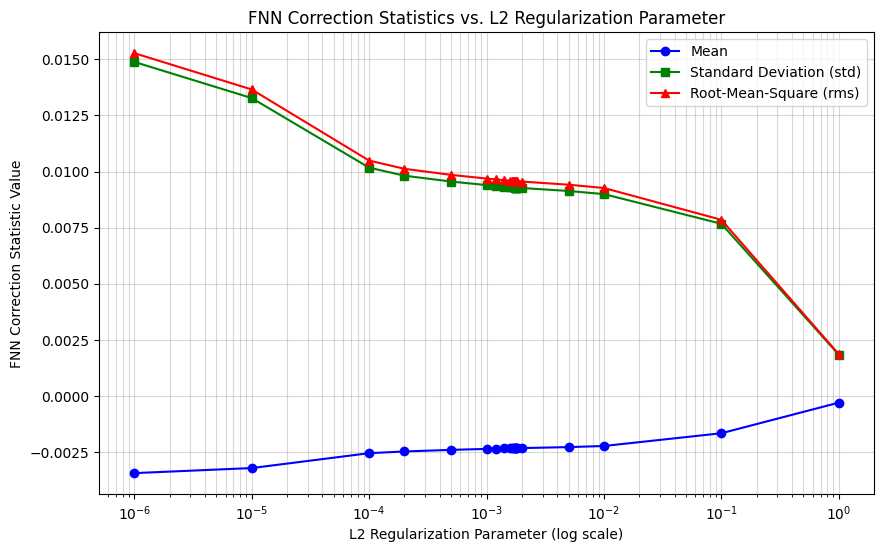

In [43]:
# Filter model_list to get the regularized GLM-NN (rglnn) models
rglnn_models = [
    m for m in model_list
    if getattr(m, 'name', None) == 'rglnn'
    and hasattr(m, 'history')
]

stats_data = []
for m in rglnn_models:
    reg_val = float(m.regularizer)
    # Calculate mean, std, and rms using the defined fnn_correction function
    f_mean, f_std, f_rms, _ = fnn_correction(m)
    stats_data.append({
        'regularizer': reg_val,
        'mean': f_mean,
        'std': f_std,
        'rms': f_rms
    })

# Create a DataFrame and sort by the L2 regularization parameter
df_stats = pd.DataFrame(stats_data).sort_values('regularizer')

# Separate zero vs non-zero for log scaling on the x-axis
non_zero_df = df_stats[df_stats['regularizer'] > 0]
zero_df = df_stats[df_stats['regularizer'] == 0]

plt.figure(figsize=(10, 6))

# Plot the three statistics
plt.plot(non_zero_df['regularizer'], non_zero_df['mean'], 'o-', color='blue', label='Mean')
plt.plot(non_zero_df['regularizer'], non_zero_df['std'], 's-', color='green', label='Standard Deviation (std)')
plt.plot(non_zero_df['regularizer'], non_zero_df['rms'], '^-', color='red', label='Root-Mean-Square (rms)')

plt.xscale('log')
plt.xlabel('L2 Regularization Parameter (log scale)')
plt.ylabel('FNN Correction Statistic Value')
plt.title('FNN Correction Statistics vs. L2 Regularization Parameter')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.savefig('fnn_correction_stats.pdf')
plt.show()
files.download('fnn_correction_stats.pdf')

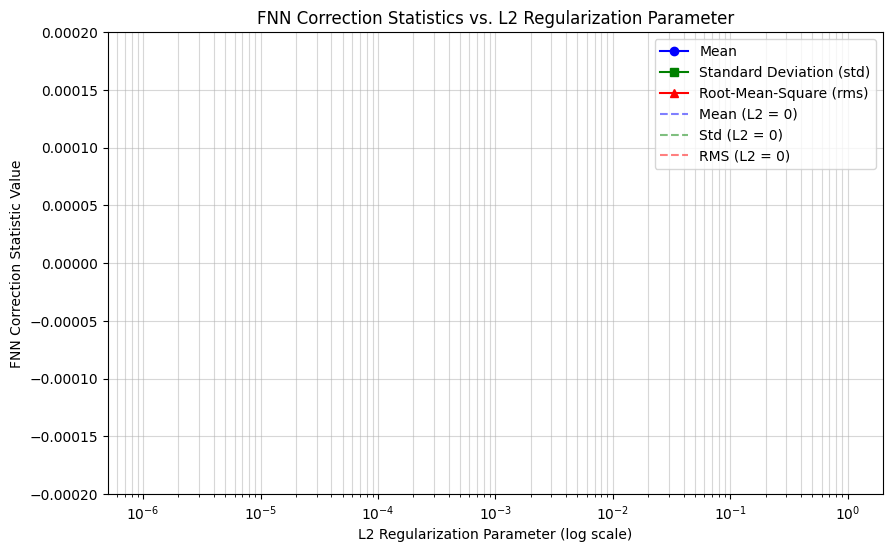

In [44]:
# Filter model_list to get the regularized GLM-NN (rglnn) models
rglnn_models = [
    m for m in model_list
    if getattr(m, 'name', None) == 'rglnn'
    and hasattr(m, 'history')
]

stats_data = []
for m in rglnn_models:
    reg_val = float(m.regularizer)
    # Calculate mean, std, and rms using the defined fnn_correction function
    f_mean, f_std, f_rms, _ = fnn_correction(m)
    stats_data.append({
        'regularizer': reg_val,
        'mean': f_mean,
        'std': f_std,
        'rms': f_rms
    })

# Create a DataFrame and sort by the L2 regularization parameter
df_stats = pd.DataFrame(stats_data).sort_values('regularizer')

# Separate zero vs non-zero for log scaling on the x-axis
non_zero_df = df_stats[df_stats['regularizer'] > 0]
zero_df = df_stats[df_stats['regularizer'] == 0]

plt.figure(figsize=(10, 6))

# Plot the three statistics
plt.plot(non_zero_df['regularizer'], non_zero_df['mean'], 'o-', color='blue', label='Mean')
plt.plot(non_zero_df['regularizer'], non_zero_df['std'], 's-', color='green', label='Standard Deviation (std)')
plt.plot(non_zero_df['regularizer'], non_zero_df['rms'], '^-', color='red', label='Root-Mean-Square (rms)')

# If zero regularization exists, plot as baseline horizontal lines
if not zero_df.empty:
    plt.axhline(y=zero_df['mean'].values[0], color='blue', linestyle='--', alpha=0.5, label='Mean (L2 = 0)')
    plt.axhline(y=zero_df['std'].values[0], color='green', linestyle='--', alpha=0.5, label='Std (L2 = 0)')
    plt.axhline(y=zero_df['rms'].values[0], color='red', linestyle='--', alpha=0.5, label='RMS (L2 = 0)')

plt.xscale('log')
plt.xlabel('L2 Regularization Parameter (log scale)')
plt.ylabel('FNN Correction Statistic Value')
plt.ylim(-2e-4, 2e-4)
plt.title('FNN Correction Statistics vs. L2 Regularization Parameter')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

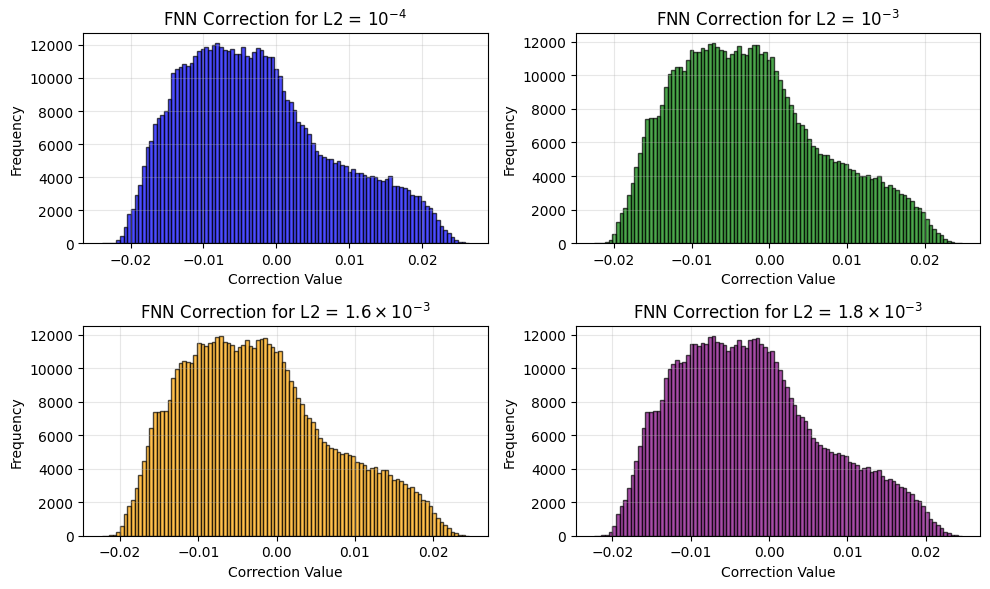

In [45]:
# Find the models for the specified L2 regularizers
model_1e4 = next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1e-4) < 1e-9)
model_1e3 = next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1e-3) < 1e-9)
model_16e3 = next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1.6e-3) < 1e-9)
model_18e3 = next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1.8e-3) < 1e-9)

# Compute fnn_eta for all models using the defined fnn_correction function
_, _, _, fnn_eta_1e4 = fnn_correction(model_1e4)
_, _, _, fnn_eta_1e3 = fnn_correction(model_1e3)
_, _, _, fnn_eta_16e3 = fnn_correction(model_16e3)
_, _, _, fnn_eta_18e3 = fnn_correction(model_18e3)

# Create a 2x2 grid of histograms
fig, axes = plt.subplots(2, 2, figsize=(10,6))

# Subplot 1: L2 = 1e-4
axes[0, 0].hist(fnn_eta_1e4, bins=100, color='blue', alpha=0.7, edgecolor='black')
axes[0, 0].set_title('FNN Correction for L2 = $10^{-4}$')
axes[0, 0].set_xlabel('Correction Value')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].grid(True, alpha=0.3)

# Subplot 2: L2 = 1e-3
axes[0, 1].hist(fnn_eta_1e3, bins=100, color='green', alpha=0.7, edgecolor='black')
axes[0, 1].set_title('FNN Correction for L2 = $10^{-3}$')
axes[0, 1].set_xlabel('Correction Value')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].grid(True, alpha=0.3)

# Subplot 3: L2 = 1.6e-3
axes[1, 0].hist(fnn_eta_16e3, bins=100, color='orange', alpha=0.7, edgecolor='black')
axes[1, 0].set_title('FNN Correction for L2 = $1.6 \\times 10^{-3}$')
axes[1, 0].set_xlabel('Correction Value')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(True, alpha=0.3)

# Subplot 4: L2 = 1.8e-3
axes[1, 1].hist(fnn_eta_18e3, bins=100, color='purple', alpha=0.7, edgecolor='black')
axes[1, 1].set_title('FNN Correction for L2 = $1.8 \\times 10^{-3}$')
axes[1, 1].set_xlabel('Correction Value')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fnn_correction_histograms.pdf')
plt.show()
files.download('fnn_correction_histograms.pdf')

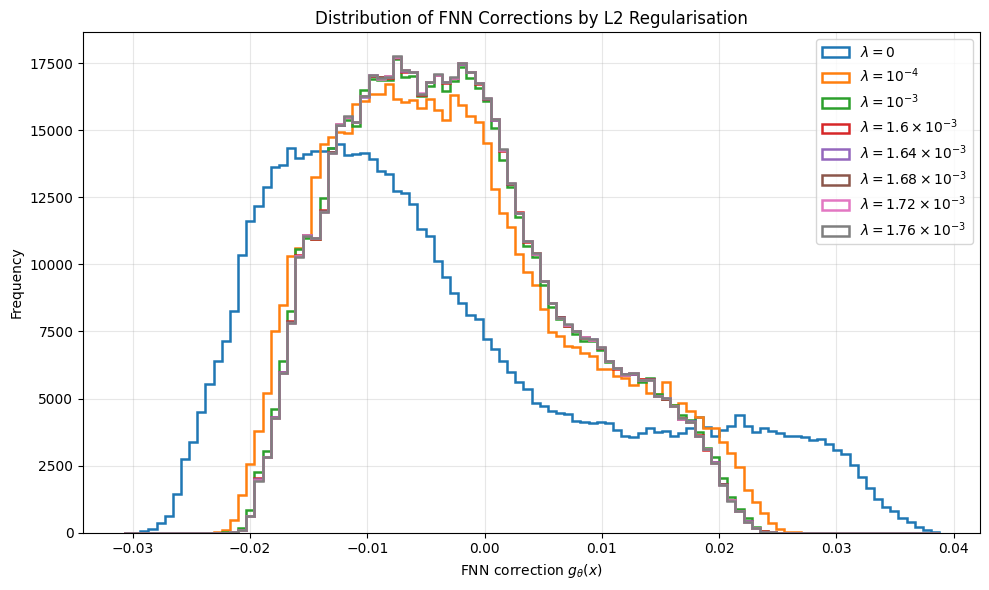

In [46]:
_, _, _, fnn_eta_zero = fnn_correction(next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer)) < 1e-9))
_, _, _, fnn_eta_164 = fnn_correction(next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1.64e-3) < 1e-9))
_, _, _, fnn_eta_168 = fnn_correction(next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1.68e-3) < 1e-9))
_, _, _, fnn_eta_172 = fnn_correction(next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1.72e-3) < 1e-9))
_, _, _, fnn_eta_176 = fnn_correction(next(m for m in model_list if getattr(m, 'name', None) == 'rglnn' and abs(float(m.regularizer) - 1.76e-3) < 1e-9))

data = [
    (fnn_eta_zero, r"$\lambda=0$"),
    (fnn_eta_1e4, r"$\lambda=10^{-4}$"),
    (fnn_eta_1e3, r"$\lambda=10^{-3}$"),
    (fnn_eta_16e3, r"$\lambda=1.6\times10^{-3}$"),
    (fnn_eta_164, r"$\lambda=1.64\times10^{-3}$"),
    (fnn_eta_168, r"$\lambda=1.68\times10^{-3}$"),
    (fnn_eta_172, r"$\lambda=1.72\times10^{-3}$"),
    (fnn_eta_176, r"$\lambda=1.76\times10^{-3}$"),
]

# Common bin boundaries
values = np.concatenate([d.ravel() for d, _ in data])
bins = np.linspace(values.min(), values.max(), 101)

plt.figure(figsize=(10, 6))

for corrections, label in data:
    plt.hist(
        corrections.numpy().ravel() if hasattr(corrections, "numpy")
        else np.asarray(corrections).ravel(),
        bins=bins,
        histtype="step",
        linewidth=1.8,
        label=label
    )

plt.xlabel(r"FNN correction $g_\theta(x)$")
plt.ylabel("Frequency")
plt.title("Distribution of FNN Corrections by L2 Regularisation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

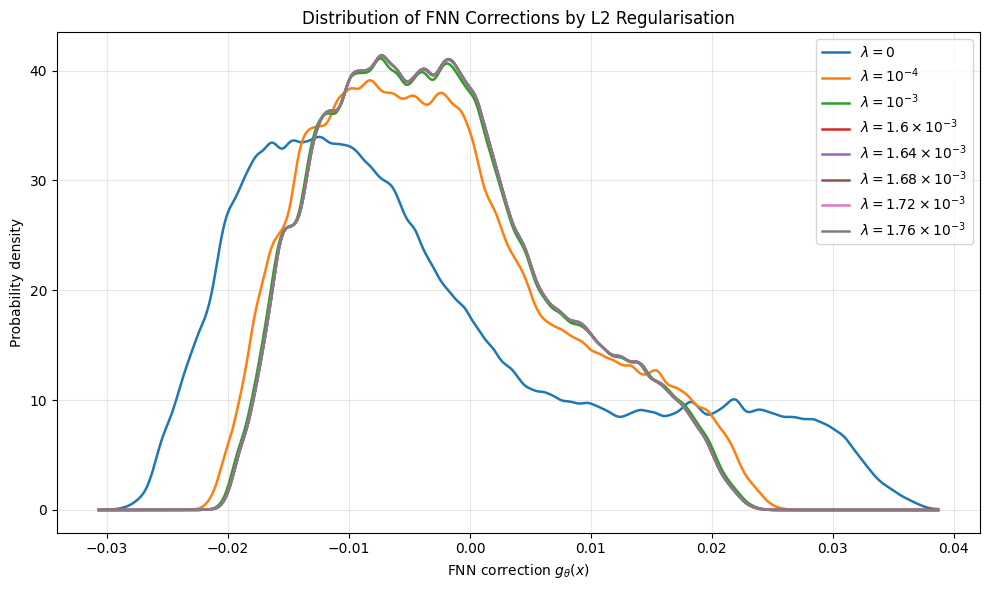

In [47]:
# Common bin boundaries
arrays = [
    d.numpy().ravel() if hasattr(d, "numpy")
    else np.asarray(d).ravel()
    for d, _ in data
]

values = np.concatenate(arrays)
bins = np.linspace(values.min(), values.max(), 501)
centres = (bins[:-1] + bins[1:]) / 2

plt.figure(figsize=(10, 6))

for (corrections, label), f in zip(data, arrays):
    density, _ = np.histogram(f, bins=bins, density=True)
    smooth = gaussian_filter1d(density, sigma=3)

    plt.plot(centres, smooth, linewidth=1.8, label=label)

plt.xlabel(r"FNN correction $g_\theta(x)$")
plt.ylabel("Probability density")
plt.title("Distribution of FNN Corrections by L2 Regularisation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()